In [1]:
# import torch
import torchvision.transforms as transforms
from torchvision import datasets
 
# loading training data
train_dataset = datasets.MNIST(root='c://pytorch//data/', 
                               train=True, 
                               transform=transforms.ToTensor(),
                               download=True)

#loading test data
test_dataset = datasets.MNIST(root='c://pytorch//data/', 
                              train=False, 
                              transform=transforms.ToTensor())

In [5]:
from torch.utils.data import DataLoader
 
# load train and test data samples into dataloader
batach_size = 32
train_loader = DataLoader(dataset=train_dataset, batch_size=batach_size, shuffle=True) 
test_loader = DataLoader(dataset=test_dataset, batch_size=batach_size, shuffle=False)


In [7]:
# build custom module for linear regression
import torch
class LinearRegression(torch.nn.Module):    
    # build the constructor
    def __init__(self, n_inputs, n_outputs):
        super(LinearRegression, self).__init__()
        self.linear = torch.nn.Linear(n_inputs, n_outputs)
    # make predictions
    def forward(self, x):
        return self.linear(x) 

In [8]:
# instantiate the model
n_inputs = 28*28 # makes a 1D vector of 784
n_outputs = 10
lin_regr = LinearRegression(n_inputs, n_outputs)

Epoch: 0. Loss: 1.1120091676712036. Accuracy: 81.17
Epoch: 1. Loss: 0.9885740876197815. Accuracy: 83.61
Epoch: 2. Loss: 0.8777031898498535. Accuracy: 85.38
Epoch: 3. Loss: 0.7314504384994507. Accuracy: 86.04
Epoch: 4. Loss: 0.5483540892601013. Accuracy: 86.81
Epoch: 5. Loss: 0.6895419359207153. Accuracy: 87.26
Epoch: 6. Loss: 0.36150431632995605. Accuracy: 87.52
Epoch: 7. Loss: 0.4486006498336792. Accuracy: 87.8
Epoch: 8. Loss: 0.30000758171081543. Accuracy: 88.09
Epoch: 9. Loss: 0.5545550584793091. Accuracy: 88.3


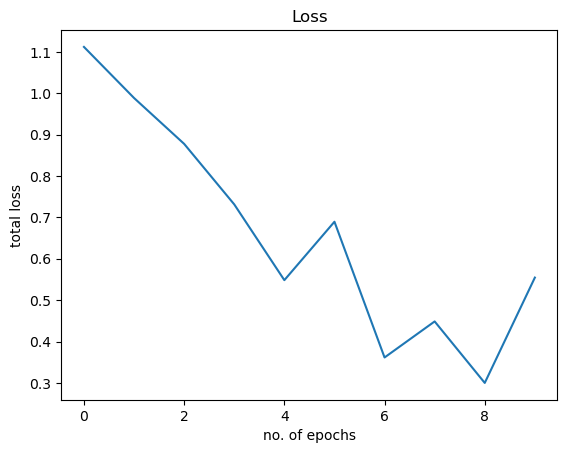

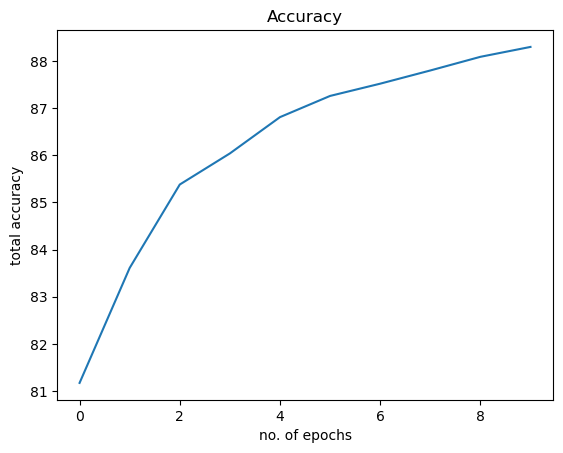

In [9]:
# defining the optimizer
optimizer = torch.optim.SGD(lin_regr.parameters(), lr=0.001)
# defining Cross-Entropy loss
criterion = torch.nn.CrossEntropyLoss()
 
epochs = 10
Loss = []
acc = []
for epoch in range(epochs):
    for i, (images, labels) in enumerate(train_loader):
        optimizer.zero_grad()
        outputs = lin_regr(images.view(-1, 28*28))
        loss = criterion(outputs, labels)
        # Loss.append(loss.item())
        loss.backward()
        optimizer.step()
    Loss.append(loss.item())
    correct = 0
    for images, labels in test_loader:
        outputs = lin_regr(images.view(-1, 28*28))
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels).sum()
    accuracy = 100 * (correct.item()) / len(test_dataset)
    acc.append(accuracy)
    print('Epoch: {}. Loss: {}. Accuracy: {}'.format(epoch, loss.item(), accuracy))

plt.plot(Loss)
plt.xlabel("no. of epochs")
plt.ylabel("total loss")
plt.title("Loss")
plt.show()
 
plt.plot(acc)
plt.xlabel("no. of epochs")
plt.ylabel("total accuracy")
plt.title("Accuracy")
plt.show()